# Osservazione sulla max_length

In [ ]:
import pandas as pd
from transformers import RobertaTokenizer

from google.colab import drive
drive.mount('/content/drive')

base_dir = "/content/drive/MyDrive/tesi/componential_model"
path_train = f"{base_dir}/data/train.tsv"
path_val = f"{base_dir}/data/dev.tsv"
path_test = f"{base_dir}/data/test.tsv"

# Carica i dati (assumendo i path corretti)
df_train = pd.read_csv(path_train, sep='\t', header=None, names=['text', 'labels', 'id'])
tokenizer = RobertaTokenizer.from_pretrained('roberta-large')

# Calcola lunghezza reale in token
lens = [len(tokenizer.encode(t, add_special_tokens=True)) for t in df_train['text']]

print(f"Lunghezza media: {sum(lens)/len(lens):.2f}")
print(f"Max assoluto: {max(lens)}")
print(f"95° percentile: {pd.Series(lens).quantile(0.95)}")
print(f"99° percentile: {pd.Series(lens).quantile(0.99)}")

# Se il 99° percentile > 48, allora max_length=48 è matematicamente un errore.

Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1437 > 512). Running this sequence through the model will result in indexing errors


Lunghezza media: 18.91
Max assoluto: 1437
95° percentile: 33.0
99° percentile: 37.0


# Preprocessing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np

run_num = 3
model_name = "roberta" # o "bert-base-uncased", etc.
dataset_name = "goemotions"
base_dir = "/content/drive/MyDrive/tesi/componential_model"

# 2. Costruisci il path dinamicamente
dinamic_path = f"{base_dir}/models/best_model_run{run_num}_{model_name}_{dataset_name}"

# (Import, definizione della classe FineTuningPipeline, ecc.)

# 1. Definisci la lista (FONDAMENTALE che l'ordine sia questo)
# Questo ordine mappa "0" -> "admiration", "1" -> "amusement", ..., "27" -> "neutral"
emotion_columns = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

path_data = "/content/drive/MyDrive/tesi/componential_model/data"

path_train = f"{base_dir}/data/train.tsv"
path_val = f"{base_dir}/data/dev.tsv"
path_test = f"{base_dir}/data/test.tsv"


# Fine-Tuning Pipeline Class RoBERTa goemotions


In [ ]:
from datetime import datetime
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader, random_split
from transformers import (
    BertForSequenceClassification,
    BertTokenizer,
    get_linear_schedule_with_warmup)


class MultiLabelFocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super(MultiLabelFocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        bce_loss = F.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-bce_loss)  # probabilità che il modello sia corretto
        focal_loss = self.alpha * (1-pt)**self.gamma * bce_loss
        return focal_loss.mean()


class FineTuningPipeline:

    def __init__(
            self,
            dataset,
            tokenizer,
            model,
            optimizer,
            columns_considered,
            save_path, # Moved save_path before parameters with default values
            loss_function = MultiLabelFocalLoss(),
            val_size = 0.2,
            epochs = 4,
            seed = 42):

        self.df_dataset = dataset
        self.tokenizer = tokenizer
        self.model = model
        self.optimizer = optimizer
        self.loss_function = loss_function
        self.columns_considered = columns_considered
        self.val_size = val_size
        self.epochs = epochs
        self.save_path = save_path
        self.seed = seed
        self.labels = torch.tensor(self.df_dataset['labels'].tolist(), dtype=torch.float32)

        # Check if GPU is available for faster training time
        if torch.cuda.is_available():
            self.device = torch.device('cuda:0')
        else:
            self.device = torch.device('cpu')

        # Perform fine-tuning
        self.model.to(self.device)
        self.set_seeds()
        self.token_ids, self.attention_masks = self.tokenize_dataset()

        self.train_dataloader, self.val_dataloader = self.create_dataloaders()
        self.scheduler = self.create_scheduler()


        self.fine_tune()

    def tokenize(self, text):
        batch_encoder = self.tokenizer.encode_plus(
            text,
            max_length = 48,
            padding = 'max_length',
            truncation = True,
            return_tensors = 'pt')
        token_ids = batch_encoder['input_ids']
        attention_mask = batch_encoder['attention_mask']
        return token_ids, attention_mask

    def tokenize_dataset(self):
        token_ids = []
        attention_masks = []
        for review in self.df_dataset['text']:
            tokens, masks = self.tokenize(review)
            token_ids.append(tokens)
            attention_masks.append(masks)
        token_ids = torch.cat(token_ids, dim=0)
        attention_masks = torch.cat(attention_masks, dim=0)
        return token_ids, attention_masks

    def _calculate_loss_weights(self, df_train):
        """Calcola i pesi BCE e li imposta in self.loss_function."""
        print("Calcolo dei pesi per la loss function...")
        # Usa le colonne passate in __init__
        pos_counts = df_train[self.columns_considered].sum()
        neg_counts = len(df_train) - pos_counts

        # Metodo 0 Aggiungi epsilon per evitare divisione per zero se una classe ha 0 esempi
        # pos_weight = neg_counts / (pos_counts + 1e-8)
        # pos_weight_tensor = torch.tensor(pos_weight.values, dtype=torch.float32).to(self.device)

        # Metodo 1
        pos_weight_raw = neg_counts / (pos_counts + 1e-8)
        pos_weight = pos_weight_raw.values
        pos_weight_tensor = torch.tensor(pos_weight, dtype=torch.float32).to(self.device)

        # Imposta la loss function come attributo della classe
        self.loss_function = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

    def create_dataloaders(self):
        full_dataset = TensorDataset(self.token_ids, self.attention_masks, self.labels)
        train_size = int((1 - self.val_size) * len(full_dataset))
        val_size = len(full_dataset) - train_size
        train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

        # --- MODIFICA FONDAMENTALE: VIA QUESTO BLOCCO ---
        # Non calcoliamo pesi perché usiamo la Focal Loss che si autobilancia.
        # train_indices = train_dataset.indices
        # df_train_per_pesi = self.df_dataset.iloc[train_indices]
        # self._calculate_loss_weights(df_train_per_pesi)
        # ------------------------------------------------

        train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=16)
        val_dataloader = DataLoader(val_dataset, batch_size=16)
        return train_dataloader, val_dataloader

    def create_scheduler(self):
        num_training_steps = self.epochs * len(self.train_dataloader)
        num_warmup_steps = int(0.1 * num_training_steps)
        scheduler = get_linear_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=num_warmup_steps,
            num_training_steps=num_training_steps)
        return scheduler

    def set_seeds(self):
        np.random.seed(self.seed)
        torch.manual_seed(self.seed)
        torch.cuda.manual_seed_all(self.seed)

    def fine_tune(self):
        # Massimizziamo F1-Macro per garantire performance sulle classi rare
        best_val_f1_macro = 0.0
        t0_train = datetime.now()

        print(f"Inizio Training su {len(self.train_dataloader)} batch per epoca...")

        for epoch in range(self.epochs):
            # ========================================
            #               Training
            # ========================================
            self.model.train()
            total_train_loss = 0
            t0_epoch = datetime.now()

            print(f'\n{"-"*20} Epoch {epoch+1}/{self.epochs} {"-"*20}')

            for step, batch in enumerate(self.train_dataloader):
                # Stampa progressiva ogni 40 batch
                if step % 40 == 0 and step > 0:
                    elapsed = datetime.now() - t0_epoch
                    print(f"  Batch {step:>5,}  -  Elapsed: {elapsed}")

                # Sposta i tensori sulla GPU
                b_input_ids = batch[0].to(self.device)
                b_input_mask = batch[1].to(self.device)
                b_labels = batch[2].to(self.device)

                # Azzera i gradienti
                self.model.zero_grad()

                # Forward pass
                # Nel loop training:
                outputs = self.model(b_input_ids, attention_mask=b_input_mask) # Niente labels=...
                loss = self.loss_function(outputs.logits, b_labels)

                total_train_loss += loss.item()

                # Backward pass
                loss.backward()

                # Clip dei gradienti a 1.0 per evitare esplosioni
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)

                # Update parametri e learning rate
                self.optimizer.step()
                self.scheduler.step()

            avg_train_loss = total_train_loss / len(self.train_dataloader)
            print(f"\n  Average training loss: {avg_train_loss:.4f}")
            print(f"  Training epoch duration: {datetime.now() - t0_epoch}")

            # ========================================
            #               Validation
            # ========================================
            print("\nInizio Validazione...")
            self.model.eval()

            # Accumulatori per calcolo metriche globale (su CPU)
            all_preds = []
            all_labels = []
            total_val_loss = 0

            for batch in self.val_dataloader:
                b_input_ids = batch[0].to(self.device)
                b_input_mask = batch[1].to(self.device)
                b_labels = batch[2].to(self.device)

            with torch.no_grad():
                # 1. Non passare le labels, così il modello non calcola la loss interna
                outputs = self.model(
                    b_input_ids,
                    token_type_ids=None,
                    attention_mask=b_input_mask
                )
                logits = outputs.logits

                # 2. Calcola la loss manualmente con la tua Focal Loss
                loss = self.loss_function(logits, b_labels)

                total_val_loss += loss.item()

                # Spostiamo su CPU subito per liberare memoria GPU
                # E accumuliamo per il calcolo finale
                all_preds.append(logits.detach().cpu())
                all_labels.append(b_labels.detach().cpu())

            # Calcolo Loss Media
            avg_val_loss = total_val_loss / len(self.val_dataloader)

            # Concatenazione finale per metriche
            all_preds = torch.cat(all_preds, dim=0) # Diventa un tensore unico (N_samples, 28)
            all_labels = torch.cat(all_labels, dim=0)

            # Usiamo la funzione completa definita prima
            metrics = self.calculate_comprehensive_metrics(all_preds, all_labels)

            print(f"  Validation Loss: {avg_val_loss:.4f}")
            print(f"  F1 Macro: {metrics['f1_macro']:.4f} | F1 Micro: {metrics['f1_micro']:.4f}")
            print(f"  Accuracy Exact: {metrics['accuracy_exact']:.4f}")

            # LOGICA DI SALVATAGGIO (Basata su F1 Macro)
            if metrics['f1_macro'] > best_val_f1_macro:
                print(f"\n⭐ NUOVO RECORD! F1 Macro migliorato: {best_val_f1_macro:.4f} -> {metrics['f1_macro']:.4f}")
                best_val_f1_macro = metrics['f1_macro']

                if not os.path.exists(self.save_path):
                    os.makedirs(self.save_path)

                print(f"  Salvataggio modello in {self.save_path}...")
                # Salviamo usando save_pretrained (standard HuggingFace)
                self.model.save_pretrained(self.save_path)
                self.tokenizer.save_pretrained(self.save_path)
            else:
                print(f"\n  Nessun miglioramento (Best F1 Macro: {best_val_f1_macro:.4f})")

        print(f'\nTraining completato in totale: {datetime.now()-t0_train}')

    def calculate_comprehensive_metrics(self, preds, labels):
        """
        Calcola metriche complete per Multi-Label Classification (GoEmotions).
        preds: Logits grezzi dal modello (non ancora passati per sigmoid)
        labels: Tensore di 0 e 1 (One-hot encoding delle emozioni)
        """
        # 1. Gestione Tensori: Stacca dal grafo, porta su CPU
        # Se sono già numpy, il codice funziona ugualmente o si adatta
        if isinstance(preds, torch.Tensor):
            preds = preds.detach().cpu()
            labels = labels.detach().cpu()

        # 2. Sigmoid e Soglia
        # Trasforma logits in probabilità e poi in 0/1
        probs = torch.sigmoid(preds)
        y_pred = (probs > 0.5).int().numpy()
        y_true = labels.numpy()

        metrics = {}

        # --- MICRO (Globale) ---
        # Utile per la performance generale, pesata sulla frequenza dei campioni
        metrics['f1_micro'] = f1_score(y_true, y_pred, average='micro', zero_division=0)
        metrics['prec_micro'] = precision_score(y_true, y_pred, average='micro', zero_division=0)
        metrics['rec_micro'] = recall_score(y_true, y_pred, average='micro', zero_division=0)

        # --- MACRO (Media delle classi) ---
        # CRUCIALE per GoEmotions: tratta ogni emozione con lo stesso peso.
        # Se fa schifo qui, il modello ignora le classi rare.
        metrics['f1_macro'] = f1_score(y_true, y_pred, average='macro', zero_division=0)
        metrics['prec_macro'] = precision_score(y_true, y_pred, average='macro', zero_division=0)
        metrics['rec_macro'] = recall_score(y_true, y_pred, average='macro', zero_division=0)

        # --- ACCURACY (Subset Accuracy) ---
        # In multi-label, conta 1 solo se TUTTE le etichette predette per una frase sono identiche a quelle vere.
        # È molto severa, ma è l'unica "vera" accuracy.
        metrics['accuracy_exact'] = accuracy_score(y_true, y_pred)

        return metrics

    # MODIFICATO: La funzione predict ora è più utile
    def predict(self, dataloader):
        """Restituisce sia le probabilità che le etichette binarie previste in modo sicuro per la memoria."""
        self.model.eval()
        all_logits = []

        # Disabilita il calcolo del gradiente per risparmiare memoria e calcoli
        with torch.no_grad():
            for batch in dataloader:
                batch_token_ids = batch[0].to(self.device)
                batch_attention_mask = batch[1].to(self.device)

                outputs = self.model(batch_token_ids, attention_mask=batch_attention_mask)
                logits = outputs.logits

                # CRUCIALE: Sposta subito su CPU per liberare la VRAM della GPU
                all_logits.append(logits.detach().cpu())

        # Concatena tutto sulla CPU (sicuro anche per dataset grandi)
        all_logits = torch.cat(all_logits, dim=0)

        # Calcola le probabilità (Sigmoid) e le classi (Soglia 0.5)
        probabilities = torch.sigmoid(all_logits).numpy()
        predictions = (probabilities > 0.5).astype(int)

        return predictions, probabilities

In [ ]:
class MultiLabelFocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0):
        super(MultiLabelFocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        bce_loss = F.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-bce_loss)  # probabilità che il modello sia corretto
        focal_loss = self.alpha * (1-pt)**self.gamma * bce_loss
        return focal_loss.mean()

# Nel tuo training loop usa:
# criterion = MultiLabelFocalLoss()

# Fine-tuning the goemotions Dataset:

num labels = 28, calcolo pesi loss function perchè la probabilità di neutral è molto alta se non utilizzo dei pesi per la loss function

In [ ]:
def preprocess_goemotions_tsv(path, emotion_list):
    """
    Carica un file .tsv di GoEmotions e lo trasforma nel formato
    DataFrame (multi-hot) richiesto dalla pipeline.
    """
    try:
        # 1. Carica il TSV (non ha header)
        df = pd.read_csv(
            path,
            sep='\t',
            header=None,
            names=['text', 'label_indices_str', 'id']
        )
    except FileNotFoundError:
        print(f"ERRORE: File non trovato a questo percorso: {path}")
        return None

    # Lista che conterrà le liste binarie (es. [0, 1, 0, ...])
    labels_multi_hot_list = []

    # 2. Prepara le 28 colonne con i nomi, inizializzate a 0
    # Questo serve per il calcolo dei 'pos_weight' nella pipeline
    for col in emotion_list:
        df[col] = 0

    num_labels = len(emotion_list)

    # 3. Itera per processare le etichette
    for index, row in df.iterrows():
        # Crea il vettore binario [0, 0, ..., 0]
        label_vector = np.zeros(num_labels, dtype=int)

        # Prendi la stringa "2,15,27"
        indices_str = str(row['label_indices_str']) # Assicura sia stringa

        # Splitta sulla virgola e converti in int
        try:
            indices = [int(i) for i in indices_str.split(',')]
        except ValueError:
            print(f"Errore riga {index}, indice non valido: {indices_str}. Riga saltata.")
            indices = []

        # 4. Attiva i bit corretti nel vettore
        for idx in indices:
            if 0 <= idx < num_labels:
                label_vector[idx] = 1

                # 5. Aggiorna anche le colonne con i nomi (per i pos_weight)
                col_name = emotion_list[idx]
                df.at[index, col_name] = 1

        labels_multi_hot_list.append(label_vector.tolist())

    # 6. Aggiungi la colonna 'labels' (la lista di liste binarie)
    #    che la pipeline usa per creare i tensori
    df['labels'] = labels_multi_hot_list

    # Rimuovi la colonna stringa che non serve più
    df = df.drop(columns=['label_indices_str'])

    return df

# 2. Carica e processa i NUOVI file usando la nuova funzione
print("Processo il 'train.tsv'...")
df_train_new = preprocess_goemotions_tsv(path_train, emotion_columns)

print("Processo il 'dev.tsv' (validazione)...")
df_val_new = preprocess_goemotions_tsv(path_val, emotion_columns)

print("Processo il 'test.tsv'...")
df_test_new = preprocess_goemotions_tsv(path_test, emotion_columns)

# 3. Ricrea i set che la tua pipeline si aspetta
# Unisci train e val per creare il blocco da cui la pipeline farà lo split
df_train_val = pd.concat([df_train_new, df_val_new], ignore_index=True)

# Il test set ora è separato e pulito
df_test = df_test_new

print(f"Dati di training/validation pronti: {len(df_train_val)} righe")
print(f"Dati di test pronti: {len(df_test)} righe")


# 4. Chiama la tua pipeline (es. con RoBERTa)
from transformers import RobertaTokenizer, RobertaForSequenceClassification
from torch.optim import AdamW

print("Inizializzazione con roberta-large...")
tokenizer = RobertaTokenizer.from_pretrained('roberta-large')
model = RobertaForSequenceClassification.from_pretrained(
    'roberta-large',
    num_labels=28
)
optimizer = AdamW(model.parameters(), lr=1e-5)

fine_tuned_model = FineTuningPipeline(
    dataset = df_train_val, # <-- Usa il nuovo dataframe
    tokenizer = tokenizer,
    model = model,
    optimizer = optimizer,
    columns_considered = emotion_columns,
    val_size = 0.1, # <-- 0.1 è più corretto (dev.tsv è il 10% del totale)
    epochs = 4,
    seed = 42,
    save_path = dinamic_path
)

# 5. DOPO il training, usa il nuovo 'df_test'
#    per lo script di test finale (quello con le soglie)
# (Il 'df_test' ora è in memoria, pronto per essere usato)

Processo il 'train.tsv'...
Processo il 'dev.tsv' (validazione)...
Processo il 'test.tsv'...
Dati di training/validation pronti: 48836 righe
Dati di test pronti: 5427 righe
Inizializzazione con roberta-large...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Inizio Training su 2747 batch per epoca...

-------------------- Epoch 1/4 --------------------
  Batch    40  -  Elapsed: 0:00:20.445545
  Batch    80  -  Elapsed: 0:00:40.134614
  Batch   120  -  Elapsed: 0:01:00.029549
  Batch   160  -  Elapsed: 0:01:20.119798
  Batch   200  -  Elapsed: 0:01:40.382616
  Batch   240  -  Elapsed: 0:02:00.724394
  Batch   280  -  Elapsed: 0:02:21.218284
  Batch   320  -  Elapsed: 0:02:41.844178
  Batch   360  -  Elapsed: 0:03:02.534283
  Batch   400  -  Elapsed: 0:03:23.184376
  Batch   440  -  Elapsed: 0:03:43.776895
  Batch   480  -  Elapsed: 0:04:04.430789
  Batch   520  -  Elapsed: 0:04:25.073176
  Batch   560  -  Elapsed: 0:04:45.735169
  Batch   600  -  Elapsed: 0:05:06.389588
  Batch   640  -  Elapsed: 0:05:27.017519
  Batch   680  -  Elapsed: 0:05:47.652187
  Batch   720  -  Elapsed: 0:06:08.352044
  Batch   760  -  Elapsed: 0:06:29.023280
  Batch   800  -  Elapsed: 0:06:49.633241
  Batch   840  -  Elapsed: 0:07:10.263348
  Batch   880  -  Elap

# Test set del modello

Dataset/Task|Tipo di Output|Loss Function Consigliata|Perché?|
| :--- | :--- | :--- | :--- |
GoEmotions|Classificazione (0/1)|BCEWithLogitsLoss(pos_weight=...)|"Dataset sbilanciato| serve aiutare le classi rare."
EmoBank|Regressione (float)|nn.MSELoss()|Devi minimizzare la distanza tra il valore predetto e quello reale.
EmoBank (Valutazione)|Regressione (float)|Pearson Correlation|"Ti interessa il trend (se sale uno, sale l'altro), non l'errore puntuale."



| Metrica | Cosa ti dice | Consigliato per te? |
| :--- | :--- | :--- |
| **Micro F1** | Conta i totali globali. È una sorta di "Accuratezza globale". | **Sì**, standard per report generali. |
| **Macro F1** | Tratta classi frequenti e rare (es. "Neutral" e "Grief") alla pari. Se il modello ignora le classi rare, questo valore crolla. | **Sì**, per dimostrare che il modello impara anche le emozioni difficili. |
| **Weighted F1** | Media pesata in base al numero di esempi. Simile al Micro ma calcolato per classe. | Spesso ridondante col Micro nei dataset grandi. |
| **Samples F1** | Qualità della predizione per singola frase (riga per riga), non per colonna. | **Assolutamente SÌ** per task Multi-Label. |

In [ ]:
dinamic_path = "/content/drive/MyDrive/tesi/componential_model/models/best_model_run3_roberta_goemotions"

In [ ]:
import torch
import numpy as np
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import f1_score, classification_report, accuracy_score

# --- 1. CONFIGURAZIONE E CARICAMENTO ---
# Imposta qui il percorso del tuo modello
model_path = dinamic_path  # Assicurati che questa variabile sia definita
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Caricamento modello da: {model_path}")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)
model.to(device)
model.eval()

# --- 2. PREPARAZIONE DATI (df_test deve essere già caricato) ---
print("Tokenizzazione Test Set...")
# Batch encoding è molto più veloce del ciclo for
encodings = tokenizer(
    df_test['text'].tolist(),
    max_length=64, # O la tua max_length specifica
    padding='max_length',
    truncation=True,
    return_tensors='pt'
)

test_labels = torch.tensor(df_test['labels'].tolist(), dtype=torch.float32)
test_dataset = TensorDataset(encodings['input_ids'], encodings['attention_mask'], test_labels)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# --- 3. INFERENZA (Raccolta Logits) ---
print("Calcolo previsioni...")
all_logits = []
all_targets = []

with torch.no_grad():
    for batch in test_dataloader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        all_logits.append(outputs.logits.cpu())
        all_targets.append(labels.cpu())

# Concatena tutto e applica Sigmoide una volta sola
all_logits = torch.cat(all_logits, dim=0)
all_probs = torch.sigmoid(all_logits).numpy()
all_targets = torch.cat(all_targets, dim=0).numpy()

# ... (Il codice precedente fino a "all_probs = torch.sigmoid(all_logits).numpy()" resta uguale) ...
# Assicurati di avere all_targets definito come numpy array (come nel tuo script originale)
# all_targets = torch.cat(all_targets, dim=0).numpy()

# ==================================================================================
# --- 4. OTTIMIZZAZIONE SOGLIE DINAMICHE (PER CLASSE) ---
# ==================================================================================
import pickle

print("\n--- INIZIO OTTIMIZZAZIONE SOGLIE SPECIFICHE ---")

# Rinomino per comodità, così combacia con il tuo snippet
all_labels = all_targets

best_thresholds = []
best_f1_scores = []

# Nomi emozioni (assicurati l'ordine sia quello del training)
emotion_names = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

print(f"{'Emotion':<15} | {'Best Thresh':<12} | {'F1 Score':<10}")
print("-" * 45)

# Cerca la soglia migliore per ogni colonna (emozione) indipendentemente
for i in range(28):
    best_t = 0.5
    best_f1 = 0.0

    # Grid search fine tra 0.1 e 0.95
    # Nota: Con Focal Loss le soglie ottimali possono essere basse (es. 0.2)
    for t in np.arange(0.1, 0.96, 0.01):
        preds = (all_probs[:, i] >= t).astype(int)
        score = f1_score(all_labels[:, i], preds, zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_t = t

    best_thresholds.append(best_t)
    best_f1_scores.append(best_f1)
    print(f"{emotion_names[i]:<15} | {best_t:.2f}         | {best_f1:.4f}")

# Salva le soglie per l'uso futuro (English documents)
with open('best_thresholds.pkl', 'wb') as f:
    pickle.dump(best_thresholds, f)
print("\n✅ Soglie ottimali salvate in 'best_thresholds.pkl'")

# ==================================================================================
# --- 5. CALCOLO DEFINITIVO METRICHE E REPORT ---
# ==================================================================================

# Costruiamo le predizioni finali usando le 28 soglie diverse
final_preds = np.zeros_like(all_probs, dtype=int)
for i in range(28):
    final_preds[:, i] = (all_probs[:, i] >= best_thresholds[i]).astype(int)

# Calcolo metriche globali
val_f1_micro    = f1_score(all_labels, final_preds, average='micro', zero_division=0)
val_f1_macro    = f1_score(all_labels, final_preds, average='macro', zero_division=0)
val_f1_weighted = f1_score(all_labels, final_preds, average='weighted', zero_division=0)
val_f1_samples  = f1_score(all_labels, final_preds, average='samples', zero_division=0)

print("-" * 30)
print(f"F1 Micro:    {val_f1_micro:.4f}")
print(f"F1 Macro:    {val_f1_macro:.4f}  <-- Questo deve essere alto!")
print(f"F1 Weighted: {val_f1_weighted:.4f}")
print(f"F1 Samples:  {val_f1_samples:.4f}")
print("-" * 30)

print("\n" + "="*30)
print(" REPORT DETTAGLIATO PER CLASSE ")
print("="*30)
print(classification_report(
    all_labels,
    final_preds,
    target_names=emotion_names,
    zero_division=0
))

Caricamento modello da: /content/drive/MyDrive/tesi/componential_model/models/best_model_run3_roberta_goemotions
Tokenizzazione Test Set...
Calcolo previsioni...

--- INIZIO OTTIMIZZAZIONE SOGLIE SPECIFICHE ---
Emotion         | Best Thresh  | F1 Score  
---------------------------------------------
admiration      | 0.51         | 0.7165
amusement       | 0.47         | 0.8414
anger           | 0.52         | 0.5174
annoyance       | 0.39         | 0.4043
approval        | 0.39         | 0.4476
caring          | 0.49         | 0.4639
confusion       | 0.42         | 0.4898
curiosity       | 0.42         | 0.6067
desire          | 0.45         | 0.5811
disappointment  | 0.39         | 0.4014
disapproval     | 0.42         | 0.4498
disgust         | 0.44         | 0.5469
embarrassment   | 0.31         | 0.5000
excitement      | 0.43         | 0.4683
fear            | 0.42         | 0.7531
gratitude       | 0.55         | 0.9219
grief           | 0.53         | 0.4444
joy             | 0

# Creiamo english_document_con_goemotions.xlxl con focal loss

Ho ottimizzato le soglie massimizzando l'F2-Score per privilegiare la sensibilità (Recall) rispetto alla precisione, dato che l'obiettivo è l'estrazione di segnali latenti.



In [ ]:
import torch
import pandas as pd
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Configurazione
base_dir = "/content/drive/MyDrive/tesi/componential_model"
# Assicurati che dinamic_path sia corretto
dinamic_path = f"{base_dir}/models/best_model_run3_roberta_goemotions"
path_test = f"{base_dir}/data/test.tsv" # Il file con le risposte vere

# 2. Carica Modello
print("Caricamento modello per ottimizzazione...")
tokenizer = AutoTokenizer.from_pretrained(dinamic_path)
model = AutoModelForSequenceClassification.from_pretrained(dinamic_path)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

# 3. Funzione per caricare il Test Set (GoEmotions)
def load_goemotions_test(path):
    df = pd.read_csv(path, sep='\t', header=None, names=['text', 'labels_str', 'id'])
    emotion_list = [
        'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
        'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
        'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
        'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
        'relief', 'remorse', 'sadness', 'surprise', 'neutral'
    ]
    # One-hot encoding manuale veloce
    labels_matrix = []
    for s in df['labels_str']:
        idx = [int(x) for x in str(s).split(',')]
        row = [0] * 28
        for i in idx:
            if i < 28: row[i] = 1
        labels_matrix.append(row)
    return df['text'].tolist(), np.array(labels_matrix)

print("Caricamento Test Set...")
test_texts, test_labels_real = load_goemotions_test(path_test)

# 4. Inferenza sul Test Set
print("Tokenizzazione Test Set...")
inputs = tokenizer(test_texts, padding='max_length', truncation=True, max_length=128, return_tensors='pt') # max_length 128 per test GoEmotions
dataset = TensorDataset(inputs['input_ids'], inputs['attention_mask'])
loader = DataLoader(dataset, batch_size=64, shuffle=False)

print("Calcolo probabilità sul Test Set...")
probs_list = []
with torch.no_grad():
    for batch in loader:
        b_ids, b_mask = batch[0].to(device), batch[1].to(device)
        out = model(b_ids, attention_mask=b_mask)
        probs_list.append(torch.sigmoid(out.logits).cpu())

# DEFINISCI LE VARIABILI CHE MANCAVANO
all_probs = torch.cat(probs_list, dim=0).numpy()
all_labels = test_labels_real # Le risposte vere
print("✅ Dati per l'ottimizzazione pronti.")

Caricamento modello per ottimizzazione...
Caricamento Test Set...
Tokenizzazione Test Set...
Calcolo probabilità sul Test Set...
✅ Dati per l'ottimizzazione pronti.


In [ ]:
from sklearn.metrics import fbeta_score
import numpy as np

print("\n--- CALCOLO SOGLIE F2 (Alta Sensibilità) ---")

best_thresholds_f2 = []
emotion_names = [ 'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral']

BETA = 2.0

for i in range(28):
    best_t = 0.5
    best_score = 0.0

    # Grid search
    for t in np.arange(0.05, 0.95, 0.01):
        preds = (all_probs[:, i] >= t).astype(int)
        score = fbeta_score(all_labels[:, i], preds, beta=BETA, zero_division=0)

        if score > best_score:
            best_score = score
            best_t = t

    best_thresholds_f2.append(best_t)
    print(f"{emotion_names[i]:<15} | Soglia F2: {best_t:.2f} | Score: {best_score:.4f}")

print("\n✅ Soglie calcolate e memorizzate in 'best_thresholds_f2'")


--- CALCOLO SOGLIE F2 (Alta Sensibilità) ---
admiration      | Soglia F2: 0.33 | Score: 0.7729
amusement       | Soglia F2: 0.37 | Score: 0.8971
anger           | Soglia F2: 0.34 | Score: 0.6209
annoyance       | Soglia F2: 0.33 | Score: 0.5166
approval        | Soglia F2: 0.30 | Score: 0.5428
caring          | Soglia F2: 0.35 | Score: 0.5489
confusion       | Soglia F2: 0.30 | Score: 0.5567
curiosity       | Soglia F2: 0.25 | Score: 0.7276
desire          | Soglia F2: 0.31 | Score: 0.6040
disappointment  | Soglia F2: 0.32 | Score: 0.4358
disapproval     | Soglia F2: 0.32 | Score: 0.5378
disgust         | Soglia F2: 0.29 | Score: 0.5966
embarrassment   | Soglia F2: 0.22 | Score: 0.5088
excitement      | Soglia F2: 0.29 | Score: 0.5441
fear            | Soglia F2: 0.32 | Score: 0.7801
gratitude       | Soglia F2: 0.42 | Score: 0.9208
grief           | Soglia F2: 0.29 | Score: 0.4255
joy             | Soglia F2: 0.42 | Score: 0.6808
love            | Soglia F2: 0.38 | Score: 0.8824
nerv

In [ ]:
import pandas as pd
import re
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# --- CONFIGURAZIONE ---
new_df = pd.read_excel('/content/drive/MyDrive/tesi/analysis/data/english_documents_cleaned.xlsx')

# Nota: Il modello e tokenizer sono già caricati nella Cella 1, li riusiamo per risparmiare tempo/memoria
print("Tokenizzazione Excel...")
encoded_texts = tokenizer(
    new_df['text'].tolist(),
    padding='max_length',
    truncation=True,
    max_length=256,
    return_tensors='pt'
)

dataset_excel = TensorDataset(encoded_texts['input_ids'], encoded_texts['attention_mask'])
loader_excel = DataLoader(dataset_excel, batch_size=32)

print("Calcolo probabilità Excel...")
excel_preds = []
with torch.no_grad():
    for batch in loader_excel:
        b_ids, b_mask = batch[0].to(device), batch[1].to(device)
        out = model(b_ids, attention_mask=b_mask)
        excel_preds.append(torch.sigmoid(out.logits).cpu())

probabilities_excel = torch.cat(excel_preds, dim=0).numpy()

# --- APPLICAZIONE LOGICA SOGLIE + SOPPRESSIONE NEUTRO ---
print("Applicazione logica F2...")

emotion_columns = emotion_names # Presi dalla cella sopra
NEUTRAL_IDX = emotion_columns.index('neutral')

# Prepara le soglie rimuovendo il neutral per il confronto
thresholds_no_neutral = np.delete(best_thresholds_f2, NEUTRAL_IDX)

binary_predictions = np.zeros_like(probabilities_excel, dtype=int)

for i, probs in enumerate(probabilities_excel):
    # Rimuovi probabilità neutral per confronto
    emotions_probs = np.delete(probs, NEUTRAL_IDX)

    # Confronta con le soglie F2 specifiche
    active_emotions_mask = (emotions_probs >= thresholds_no_neutral).astype(int)

    if np.sum(active_emotions_mask) > 0:
        # Trovata emozione -> Mappa indici e spegni neutral
        current_idx = 0
        for emotion_idx in range(len(emotion_columns)):
            if emotion_idx == NEUTRAL_IDX:
                binary_predictions[i, emotion_idx] = 0
            else:
                binary_predictions[i, emotion_idx] = active_emotions_mask[current_idx]
                current_idx += 1
    else:
        # Deserto emotivo -> Accendi neutral
        binary_predictions[i, NEUTRAL_IDX] = 1

# --- SALVATAGGIO ---
for i, emotion in enumerate(emotion_columns):
    new_df[f'{emotion}_pred'] = binary_predictions[:, i]

predicted_list = []
labels_arr = np.array(emotion_columns)
for row in binary_predictions:
    predicted_list.append(labels_arr[row == 1].tolist())
new_df['predicted_emotions'] = predicted_list

cols = ['text', 'predicted_emotions'] + [f'{e}_pred' for e in emotion_columns]
path_out = f"{base_dir}/output/english_documents_5_roberta_goemotions.xlsx"
new_df[cols].to_excel(path_out, index=False)

print(f"\n✅ Fatto! File salvato in: {path_out}")
print(new_df[['text', 'predicted_emotions']].head(10))

Tokenizzazione Excel...
Calcolo probabilità Excel...
Applicazione logica F2...

✅ Fatto! File salvato in: /content/drive/MyDrive/tesi/componential_model/output/english_documents_5_roberta_goemotions.xlsx
                                                text  \
0      not having a steady job and being paid little   
1  i agree with this definition: we speak of job ...   
2  precariousness is the lack of resources in thi...   
3  for me precariousness is the fact of not being...   
4                                     being helpless   
5                               something is missing   
6  it is not being able to live peacefully econom...   
7  not obtaining complete well-being despite the ...   
8                               the lack of security   
9  not having the power to decide to negotiate to...   

                       predicted_emotions  
0               [disappointment, sadness]  
1                              [approval]  
2               [disappointment, sadness]  
3  

## CREAZIONE ENGLISH DOC IN UN UNICO PASSSAGGIO

In [ ]:
import torch
import pandas as pd
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import fbeta_score

# ==========================================
# 1. CONFIGURAZIONE E SETUP
# ==========================================
base_dir = "/content/drive/MyDrive/tesi/componential_model"
dynamic_path = f"{base_dir}/models/best_model_run3_roberta_goemotions" # Modello addestrato (con Focal Loss)
path_test = f"{base_dir}/data/test.tsv" # Test set originale per calcolo soglie
path_excel_input = '/content/drive/MyDrive/tesi/analysis/data/english_documents_cleaned.xlsx'
path_excel_output = f"{base_dir}/output/english_documents_5_roberta_goemotions.xlsx"

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo in uso: {device}")

emotion_names = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
    'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
    'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
    'relief', 'remorse', 'sadness', 'surprise', 'neutral'
]

# ==========================================
# 2. CARICAMENTO MODELLO
# ==========================================
print("Caricamento modello e tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(dynamic_path)
model = AutoModelForSequenceClassification.from_pretrained(dynamic_path)
model.to(device)
model.eval()

# ==========================================
# 3. CALCOLO SOGLIE F2 SUL TEST SET
# ==========================================
def load_goemotions_test(path):
    df = pd.read_csv(path, sep='\t', header=None, names=['text', 'labels_str', 'id'])
    labels_matrix = []
    for s in df['labels_str']:
        idx = [int(x) for x in str(s).split(',')]
        row = [0] * 28
        for i in idx:
            if i < 28: row[i] = 1
        labels_matrix.append(row)
    return df['text'].tolist(), np.array(labels_matrix)

print("\n--- FASE 1: Calcolo Soglie Ottimali (Test Set) ---")
test_texts, test_labels_real = load_goemotions_test(path_test)

# Tokenizzazione Test Set
inputs = tokenizer(test_texts, padding='max_length', truncation=True, max_length=128, return_tensors='pt')
dataset = TensorDataset(inputs['input_ids'], inputs['attention_mask'])
loader = DataLoader(dataset, batch_size=64, shuffle=False)

# Inferenza Test Set
probs_list = []
with torch.no_grad():
    for batch in loader:
        b_ids, b_mask = batch[0].to(device), batch[1].to(device)
        out = model(b_ids, attention_mask=b_mask)
        probs_list.append(torch.sigmoid(out.logits).cpu())

all_probs = torch.cat(probs_list, dim=0).numpy()
all_labels = test_labels_real

# Calcolo F2
best_thresholds_f2 = []
BETA = 2.0
print("Calcolo best threshold per ogni emozione...")

for i in range(28):
    best_t = 0.5
    best_score = 0.0
    for t in np.arange(0.05, 0.95, 0.01):
        preds = (all_probs[:, i] >= t).astype(int)
        score = fbeta_score(all_labels[:, i], preds, beta=BETA, zero_division=0)
        if score > best_score:
            best_score = score
            best_t = t
    best_thresholds_f2.append(best_t)
    # print(f"{emotion_names[i]}: {best_t:.2f}") # Decommenta per vedere i dettagli

print("✅ Soglie calcolate.")

# ==========================================
# 4. INFERENZA SU NUOVI DATI (EXCEL)
# ==========================================
print("\n--- FASE 2: Inferenza su Excel ---")
new_df = pd.read_excel(path_excel_input)

# Tokenizzazione Excel
encoded_texts = tokenizer(
    new_df['text'].tolist(),
    padding='max_length',
    truncation=True,
    max_length=256,
    return_tensors='pt'
)
dataset_excel = TensorDataset(encoded_texts['input_ids'], encoded_texts['attention_mask'])
loader_excel = DataLoader(dataset_excel, batch_size=32)

# Inferenza Excel
excel_preds = []
with torch.no_grad():
    for batch in loader_excel:
        b_ids, b_mask = batch[0].to(device), batch[1].to(device)
        out = model(b_ids, attention_mask=b_mask)
        excel_preds.append(torch.sigmoid(out.logits).cpu())

probabilities_excel = torch.cat(excel_preds, dim=0).numpy()

# ==========================================
# 5. APPLICAZIONE LOGICA E SALVATAGGIO
# ==========================================
print("Applicazione logica soglie e pulizia Neutral...")

NEUTRAL_IDX = emotion_names.index('neutral')
binary_predictions = np.zeros_like(probabilities_excel, dtype=int)

for i, probs in enumerate(probabilities_excel):
    # Controlliamo quali emozioni specifiche superano la loro soglia F2
    active_emotions = []

    for emo_idx in range(len(emotion_names)):
        if emo_idx == NEUTRAL_IDX:
            continue # Saltiamo il controllo del neutral per ora

        if probs[emo_idx] >= best_thresholds_f2[emo_idx]:
            binary_predictions[i, emo_idx] = 1
            active_emotions.append(emo_idx)

    # LOGICA ESCLUSIVA:
    # Se abbiamo trovato almeno un'emozione attiva (diversa da neutral), neutral = 0.
    # Se NON abbiamo trovato nessuna emozione, neutral = 1 (deserto emotivo).
    if len(active_emotions) > 0:
        binary_predictions[i, NEUTRAL_IDX] = 0
    else:
        binary_predictions[i, NEUTRAL_IDX] = 1

# Creazione colonne output
for i, emotion in enumerate(emotion_names):
    new_df[f'{emotion}_pred'] = binary_predictions[:, i]

# Colonna riassuntiva (lista di stringhe)
predicted_list = []
labels_arr = np.array(emotion_names)
for row in binary_predictions:
    predicted_list.append(labels_arr[row == 1].tolist())
new_df['predicted_emotions'] = predicted_list

# Salvataggio
cols = ['text', 'predicted_emotions'] + [f'{e}_pred' for e in emotion_names]
new_df[cols].to_excel(path_excel_output, index=False)

print(f"\n✅ Fatto! File salvato in: {path_excel_output}")
print(new_df[['text', 'predicted_emotions']].head())

## Split-Half Reliability

Dimensioni Subset A: 1243
Dimensioni Subset B: 1244

--- RISULTATI DEL TEST DI STABILITÀ ---
Correlazione di Pearson (r): 0.9989
Interpretazione: > 0.9 = Eccellente, > 0.8 = Buono, < 0.7 = Instabile

Top 3 Emozioni con maggior divergenza tra i due split:
           Emotion  Subset_A (%)  Subset_B (%)  Diff (%)
27         neutral     39.903459     41.398714  1.495254
9   disappointment     22.606597     24.035370  1.428773
25         sadness     38.374899     37.218650  1.156250


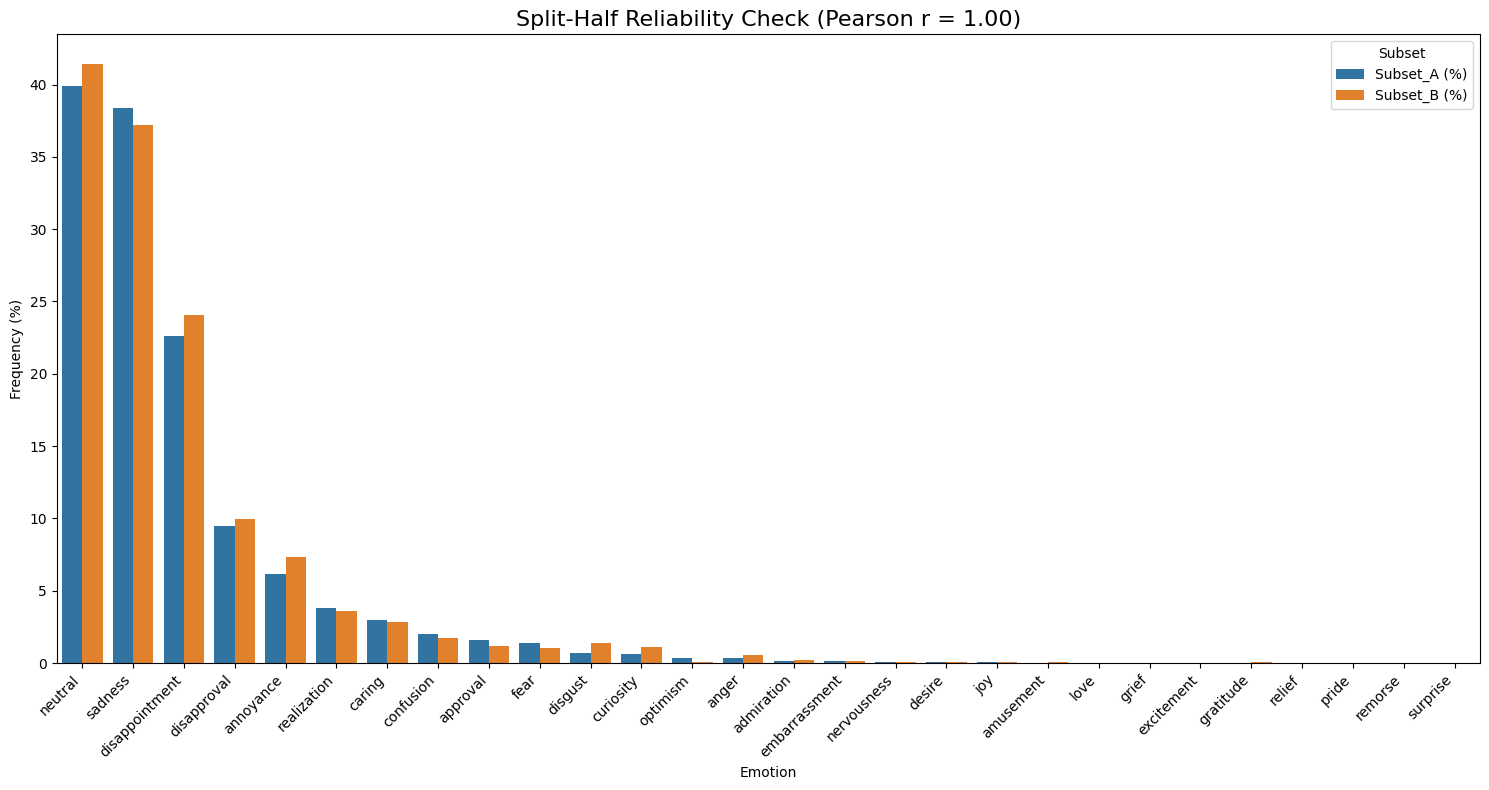

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import pandas as pd
# ---------------------------------------------------------
# 1. PREPARAZIONE DEI DATI
# ---------------------------------------------------------
# Prendiamo il dataframe finale che hai appena creato
new_df = pd.read_excel('/content/drive/MyDrive/tesi/componential_model/output/english_documents_5_roberta_goemotions.xlsx')
df_analysis = new_df.copy()

# Recuperiamo i nomi delle colonne delle emozioni (escludendo 'predicted_emotions' e testi)
# Assumiamo che le colonne binarie finiscano con '_pred' come nel tuo script
pred_cols = [col for col in df_analysis.columns if col.endswith('_pred')]

# Rimuoviamo il suffisso '_pred' per avere etichette pulite nel grafico
emotion_labels = [col.replace('_pred', '') for col in pred_cols]

# ---------------------------------------------------------
# 2. SPLIT CASUALE (50% - 50%)
# ---------------------------------------------------------
# Mescoliamo il dataset con un random_state fisso per riproducibilità
shuffled_df = df_analysis.sample(frac=1, random_state=42)

# Calcoliamo il punto di taglio a metà
split_index = int(len(shuffled_df) * 0.5)

# Creiamo i due subset
subset_A = shuffled_df.iloc[:split_index]
subset_B = shuffled_df.iloc[split_index:]

print(f"Dimensioni Subset A: {len(subset_A)}")
print(f"Dimensioni Subset B: {len(subset_B)}")

# ---------------------------------------------------------
# 3. CALCOLO DELLE FREQUENZE
# ---------------------------------------------------------
# Calcoliamo la percentuale di presenza di ogni emozione nei due subset
# (Media delle colonne binarie = Frequenza relativa)
freq_A = subset_A[pred_cols].mean() * 100
freq_B = subset_B[pred_cols].mean() * 100

# Creiamo un DataFrame riassuntivo per il confronto
comparison_df = pd.DataFrame({
    'Emotion': emotion_labels,
    'Subset_A (%)': freq_A.values,
    'Subset_B (%)': freq_B.values
})

# Aggiungiamo la differenza assoluta per vedere dove diverge di più
comparison_df['Diff (%)'] = abs(comparison_df['Subset_A (%)'] - comparison_df['Subset_B (%)'])

# ---------------------------------------------------------
# 4. ANALISI STATISTICA (CORRELAZIONE)
# ---------------------------------------------------------
# Calcoliamo la correlazione di Pearson tra le due distribuzioni
# Un valore vicino a 1.0 indica che il modello è molto stabile
corr_coef, p_value = pearsonr(comparison_df['Subset_A (%)'], comparison_df['Subset_B (%)'])

print("\n--- RISULTATI DEL TEST DI STABILITÀ ---")
print(f"Correlazione di Pearson (r): {corr_coef:.4f}")
print("Interpretazione: > 0.9 = Eccellente, > 0.8 = Buono, < 0.7 = Instabile")

# Mostriamo le emozioni con maggior divergenza (se ce ne sono)
print("\nTop 3 Emozioni con maggior divergenza tra i due split:")
print(comparison_df.sort_values(by='Diff (%)', ascending=False).head(3)[['Emotion', 'Subset_A (%)', 'Subset_B (%)', 'Diff (%)']])

# ---------------------------------------------------------
# 5. VISUALIZZAZIONE
# ---------------------------------------------------------
# Trasformiamo i dati in formato 'long' per Seaborn
df_melted = comparison_df.melt(id_vars='Emotion',
                               value_vars=['Subset_A (%)', 'Subset_B (%)'],
                               var_name='Split',
                               value_name='Frequency')

plt.figure(figsize=(15, 8))


# Ordiniamo il grafico in base alla frequenza totale per leggibilità
order = comparison_df.sort_values(by='Subset_A (%)', ascending=False)['Emotion']

sns.barplot(data=df_melted, x='Emotion', y='Frequency', hue='Split', order=order, palette=['#1f77b4', '#ff7f0e'])

plt.title(f'Split-Half Reliability Check (Pearson r = {corr_coef:.2f})', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Frequency (%)')
plt.xlabel('Emotion')
plt.legend(title='Subset')
plt.tight_layout()
plt.show()